# Objetivo
El amoníaco de los fertilizantes se fabrica con el proceso Haber-Bosch, y para mejorarlo hay que calcular bien la energía de los electrones justo cuando se rompe un enlace (como el del nitrógeno). Ahí es donde los métodos clásicos aproximados fallan.

Como versión chica del mismo problema, usamos cuatro hidrógenos en fila (H4) separados por una distancia d. Queremos la energía más baja para cada d, y de esa curva sacar la distancia de equilibrio Re y la energía de disociación De.

# Planteo base

1. Armar el Hamiltoniano de H4 para cada distancia y calcular las referencias clásicas, CCSD y FCI, con PySCF. Solo sirven para comparar.
2. Construir el VQE: ansatz químico (UCCSD) y optimizador L-BFGS-B, primero sin ruido.
3. Medir el circuito optimizado con shots y calcular la barra de error σ en cada distancia.
4. Graficar la energía, obtener Re y De, y argumentar por qué el resultado es confiable antes de compararlo con CCSD y FCI.

# Pipeline

1. Barrido de H4: base STO-3G, átomos en z = 0, d, 2d, 3d, incluyendo 1,8 Å y 3,0 Å. En cada distancia construimos el Hamiltoniano y calculamos CCSD y FCI para esa misma geometría.
2. Optimizar el VQE: arrancamos desde Hartree-Fock y los ángulos óptimos de una distancia son el punto de partida de la siguiente.
3. Medir la energía final y su incertidumbre: con los ángulos fijos, medimos con SamplerV2 de Aer (shots reales). Reportamos E_VQE con su σ, indicando los shots usados.
4. Gráfico y chequeo del desafío: las tres curvas juntas. Re sale del mínimo de la curva VQE (ajustando una parábola cerca del mínimo) y De = E_VQE(3,0 Å) - E_VQE(Re), ya que 3,0 Å es el punto de disociación.

# Stack tecnológico

* PySCF: Hartree-Fock, integrales y las referencias CCSD y FCI
* Qiskit: Hamiltoniano de qubits y circuito del ansatz
* SciPy: el optimizador L-BFGS-B
* StatevectorEstimator: solo para buscar los ángulos sin ruido
* SamplerV2 de qiskit_aer: para medir la energía final con shots. No usamos el EstimatorV2 de Aer porque no simula shots, calcula el valor exacto y le suma ruido gaussiano

#**Código**

In [2]:
#Instalación básica
%pip install -q qiskit[visualization] qiskit-aer pyscf

import numpy as np
import matplotlib.pyplot as plt
from math import comb
from scipy.optimize import minimize
from pyscf import gto, scf, fci, mcscf, ao2mo, cc
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate, efficient_su2
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator, SamplerV2 as AerSampler


Preparación de la molécula H4 con los núcleos separados por las distancias d de la grilla.

In [3]:
distancias = np.linspace(0.6, 3.0, 17).round(2)
moleculas_h4 = []

for d in distancias:
    # Cuatro hidrógenos en línea sobre el eje z.
    atomos = [("H", (0.0, 0.0, i * d)) for i in range(4)]

    mol = gto.M(
        atom=atomos,
        basis="sto-3g",
        unit="Angstrom",
        charge=0,
        spin=0,
        verbose=0,
    )
    moleculas_h4.append((d, mol))

print(f"Moléculas preparadas: {len(moleculas_h4)}")
print("Distancias entre vecinos (Å):", distancias)

d, mol = moleculas_h4[0]
print(f"\nPrimera geometría, con d = {d:.2f} Å")
print(mol.atom_coords(unit="Angstrom"))
print(f"Electrones: {mol.nelectron} | Orbitales espaciales: {mol.nao_nr()}")

Moléculas preparadas: 17
Distancias entre vecinos (Å): [0.6  0.75 0.9  1.05 1.2  1.35 1.5  1.65 1.8  1.95 2.1  2.25 2.4  2.55
 2.7  2.85 3.  ]

Primera geometría, con d = 0.60 Å
[[0.  0.  0. ]
 [0.  0.  0.6]
 [0.  0.  1.2]
 [0.  0.  1.8]]
Electrones: 4 | Orbitales espaciales: 4


Correr Hartree-Fock y construir el Hamiltoniano de cada geometría

Definir la función hamiltoniano_qubits()

In [4]:
def destruccion_jordan_wigner(p, n_qubits):
    """Operador de destrucción del spin-orbital p con el mapeo de Jordan-Wigner."""
    # Z en los qubits 0, 1, ..., p-1 y (X + iY)/2 en el qubit p
    return SparsePauliOp.from_sparse_list(
        [("Z" * p + "X", list(range(p + 1)), 0.5),
         ("Z" * p + "Y", list(range(p + 1)), 0.5j)],
        n_qubits,
    )

def hamiltoniano_qubits(m, destruccion=destruccion_jordan_wigner):
    """Arma el Hamiltoniano de la molécula m como una suma de operadores de Pauli."""
    norb = m["norb"]
    n_qubits = 2 * norb
    h, g = m["h"], m["g"]

    # Operadores de destrucción y creación de cada spin-orbital
    # Los qubits 0, ..., norb-1 son los spin-orbitales alfa y los siguientes son los beta
    a = [destruccion(p, n_qubits) for p in range(n_qubits)]
    a_dag = [op.adjoint() for op in a]

    # salto[s][p][q] mueve un electrón con spin s del orbital q al orbital p
    salto = [[[a_dag[s * norb + p].dot(a[s * norb + q]).simplify()
               for q in range(norb)] for p in range(norb)] for s in range(2)]

    # Empezamos con la parte constante (repulsión entre núcleos y orbitales congelados)
    terminos = [SparsePauliOp("I" * n_qubits, m["constante"])]

    # Saltos de un electrón
    for s in range(2):
        for p in range(norb):
            for q in range(norb):
                terminos.append(h[p, q] * salto[s][p][q])

    # Saltos de dos electrones a la vez
    for s in range(2):
        for t in range(2):
            for p in range(norb):
                for q in range(norb):
                    segundo_salto = SparsePauliOp.sum(
                        [g[p, q, r, u] * salto[t][r][u] for r in range(norb) for u in range(norb)])
                    terminos.append(0.5 * salto[s][p][q].dot(segundo_salto))
                    if s == t:
                        # Corrección por el orden de los operadores cuando los dos electrones tienen el mismo spin
                        for u in range(norb):
                            terminos.append(-0.5 * g[p, q, q, u] * salto[s][p][u])

    return SparsePauliOp.sum(terminos).simplify(atol=1e-10)

Corremos Hartree-Fock restringido (RHF) y construimos el Hamiltoniano de 8 qubits para cada distancia

In [5]:
problemas_h4 = []

for d, mol in moleculas_h4:
    hf = scf.RHF(mol).run()
    if not hf.converged:
        raise RuntimeError(f"Hartree–Fock no convergió para d = {d:.2f} Å")

    # Usamos los 4 orbitales y los 4 electrones, sin congelar orbitales.
    norb = mol.nao_nr()
    espacio_activo = mcscf.CASCI(hf, norb, mol.nelectron)
    h, constante = espacio_activo.get_h1cas()
    g = ao2mo.restore(1, espacio_activo.get_h2cas(), norb)

    datos = {
        "d": d,
        "hf": hf,
        "e_hf": hf.e_tot,
        "norb": norb,
        "nelec": mol.nelec,
        "h": h,
        "g": g,
        "constante": constante,
    }
    datos["H"] = hamiltoniano_qubits(datos)
    problemas_h4.append(datos)

print(f"Hamiltonianos preparados: {len(problemas_h4)}")
for datos in problemas_h4:
    print(
        f"d = {datos['d']:.2f} Å | "
        f"E_HF = {datos['e_hf']:.8f} Ha | "
        f"{datos['H'].num_qubits} qubits"
    )

Hamiltonianos preparados: 17
d = 0.60 Å | E_HF = -1.92956425 Ha | 8 qubits
d = 0.75 Å | E_HF = -2.10329082 Ha | 8 qubits
d = 0.90 Å | E_HF = -2.12425974 Ha | 8 qubits
d = 1.05 Å | E_HF = -2.07886255 Ha | 8 qubits
d = 1.20 Å | E_HF = -2.00386748 Ha | 8 qubits
d = 1.35 Å | E_HF = -1.91734182 Ha | 8 qubits
d = 1.50 Å | E_HF = -1.82913741 Ha | 8 qubits
d = 1.65 Å | E_HF = -1.74468604 Ha | 8 qubits
d = 1.80 Å | E_HF = -1.66686716 Ha | 8 qubits
d = 1.95 Å | E_HF = -1.59703294 Ha | 8 qubits
d = 2.10 Å | E_HF = -1.53556913 Ha | 8 qubits
d = 2.25 Å | E_HF = -1.48224255 Ha | 8 qubits
d = 2.40 Å | E_HF = -1.43645854 Ha | 8 qubits
d = 2.55 Å | E_HF = -1.39745630 Ha | 8 qubits
d = 2.70 Å | E_HF = -1.36443703 Ha | 8 qubits
d = 2.85 Å | E_HF = -1.33662923 Ha | 8 qubits
d = 3.00 Å | E_HF = -1.31331179 Ha | 8 qubits


Chequeo interno: 00110011 es el estado de Hartree-Fock de H4. Su energía calculada con nuestro Hamiltoniano de qubits debería coincidir con la energía que dio PySCF

In [6]:
from qiskit.quantum_info import Statevector

estado_hf = Statevector.from_label("00110011")

for datos in problemas_h4:
    energia = estado_hf.expectation_value(datos["H"]).real
    np.testing.assert_allclose(energia, datos["e_hf"], atol=1e-8, rtol=0)

print("Chequeo OK: el Hamiltoniano reproduce la energía HF en toda la grilla.")

Chequeo OK: el Hamiltoniano reproduce la energía HF en toda la grilla.


Armado del ansatz. Este circuito se va a constituir de una función que trabaja con calcular los saltos posibles. Estos saltos se refiere al cambio de lugar del electrón, porque podemos pensar a los orbitales como asientos para los electrones.

In [7]:
def saltos_posibles(m):
    """Lista todos los saltos de uno y de dos electrones desde Hartree-Fock."""
    norb = m["norb"]
    n_alfa, n_beta = m["nelec"]
    # Spin-orbitales ocupados y vacíos en Hartree-Fock, para cada spin
    ocupados = [list(range(n_alfa)), [norb + i for i in range(n_beta)]]
    vacios = [list(range(n_alfa, norb)), [norb + i for i in range(n_beta, norb)]]

    saltos = []
    # Un electrón salta de i a a, sin cambiar su spin
    for s in range(2):
        for i in ocupados[s]:
            for a in vacios[s]:
                saltos.append(((i,), (a,)))
    # Dos electrones de distinto spin saltan a la vez
    for i in ocupados[0]:
        for j in ocupados[1]:
            for a in vacios[0]:
                for b in vacios[1]:
                    saltos.append(((i, j), (a, b)))
    # Dos electrones del mismo spin saltan a la vez
    for s in range(2):
        for x, i in enumerate(ocupados[s]):
            for j in ocupados[s][x + 1:]:
                for y, a in enumerate(vacios[s]):
                    for b in vacios[s][y + 1:]:
                        saltos.append(((i, j), (a, b)))
    return saltos


def ansatz_ucc(m):
    """Ansatz químico que parte de Hartree-Fock y agrega un ángulo por cada salto posible."""
    norb = m["norb"]
    n_alfa, n_beta = m["nelec"]
    n_qubits = 2 * norb
    a = [destruccion_jordan_wigner(p, n_qubits) for p in range(n_qubits)]
    saltos = saltos_posibles(m)
    theta = ParameterVector("θ", len(saltos))

    circuito = QuantumCircuit(n_qubits)
    # Estado de Hartree-Fock, con X en los spin-orbitales ocupados
    for i in range(n_alfa):
        circuito.x(i)
    for i in range(n_beta):
        circuito.x(norb + i)

    for angulo, (desde, hacia) in zip(theta, saltos):
        # T saca los electrones de "desde" y los pone en "hacia"
        T = SparsePauliOp("I" * n_qubits)
        for p in hacia:
            T = T.dot(a[p].adjoint())
        for p in reversed(desde):
            T = T.dot(a[p])
        # G = i(T - T†) es hermítico, y la compuerta aplica exp(θ(T - T†))
        G = (1j * (T - T.adjoint())).simplify()
        circuito.append(PauliEvolutionGate(G, time=angulo), range(n_qubits))

    # Transpilamos una sola vez para que la simulación sea rápida
    return transpile(circuito, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)

Despues de definir las dos funciones, construimos el circuito una vez y lo dejamos listo para reutilizarlo en todo el barrido. Con "barrido" nos referimos a que vamos a usar el mismo circuito muchas veces.

In [8]:
from qiskit.quantum_info import Statevector

datos_prueba = problemas_h4[0]
ansatz_h4 = ansatz_ucc(datos_prueba)

print(f"Qubits: {ansatz_h4.num_qubits}")
print(f"Ángulos: {ansatz_h4.num_parameters}")
print(f"CNOTs: {ansatz_h4.count_ops().get('cx', 0)}")

assert ansatz_h4.num_qubits == datos_prueba["H"].num_qubits == 8
assert ansatz_h4.num_parameters == 26

# Con todos los ángulos en cero, el circuito debe preparar HF.
angulos_cero = np.zeros(ansatz_h4.num_parameters)
circuito_hf = ansatz_h4.assign_parameters(angulos_cero)
estado_hf = Statevector.from_instruction(circuito_hf)

assert estado_hf.equiv(Statevector.from_label("00110011"))

energia_cero = estado_hf.expectation_value(datos_prueba["H"]).real
np.testing.assert_allclose(
    energia_cero, datos_prueba["e_hf"], atol=1e-8, rtol=0
)

print(f"Chequeo OK: con ángulos cero, E = {energia_cero:.8f} Ha (Hartree–Fock).")

Qubits: 8
Ángulos: 26
CNOTs: 386
Chequeo OK: con ángulos cero, E = -1.92956425 Ha (Hartree–Fock).




In [9]:
ansatz_h4.draw(output="mpl", fold=30, plot_barriers=False, scale=0.7)

Dibujamos nuestro ansatz, construyéndolo con los dos datos que usa la función: 4 orbitales espaciales y 2 electrones de cada spin. Podemos observar en la salida que hay 32 filas. El asunto es que es un solo circuito de 8 qubits, con 26 parámetros, dividido en 32 filas para que entre en la pantalla. Los 26 parámetros son los 26 ángulos ajustables.



In [10]:
datos_ansatz_h4 = {"norb": 4, "nelec": (2, 2)}
ansatz_h4 = ansatz_ucc(datos_ansatz_h4)

ansatz_h4.draw(output="mpl", fold=30, scale=0.7)

Implementación de VQE a partir del ansatz efectuado. Disponemos del ansatz con 26 ángulos y el Hamiltoniano de cada distancia. Ahora, VQE los va a conectar: el circuito prepara un estado para cada conjunto de ángulos, StatevectorEstimator evalúa su energía y L-BFGS-B propone nuevos ángulos para bajarla

d = 0.60 Å | E_VQE = -1.96018780 Ha | E_CCSD = -1.96018888 Ha | E_FCI = -1.96019364 Ha | error = 0.0058 mHa | iter = 12
d = 0.75 Å | E_VQE = -2.14510091 Ha | E_CCSD = -2.14510625 Ha | E_FCI = -2.14511065 Ha | error = 0.0097 mHa | iter = 11
d = 0.90 Å | E_VQE = -2.18028194 Ha | E_CCSD = -2.18030941 Ha | E_FCI = -2.18031661 Ha | error = 0.0347 mHa | iter = 11
d = 1.05 Å | E_VQE = -2.15332490 Ha | E_CCSD = -2.15343649 Ha | E_FCI = -2.15344103 Ha | error = 0.1161 mHa | iter = 12
d = 1.20 Å | E_VQE = -2.10229358 Ha | E_CCSD = -2.10267114 Ha | E_FCI = -2.10260848 Ha | error = 0.3149 mHa | iter = 11
d = 1.35 Å | E_VQE = -2.04613487 Ha | E_CCSD = -2.04724078 Ha | E_FCI = -2.04684635 Ha | error = 0.7115 mHa | iter = 14
d = 1.50 Å | E_VQE = -1.99478317 Ha | E_CCSD = -1.99762405 Ha | E_FCI = -1.99615033 Ha | error = 1.3672 mHa | iter = 19
d = 1.65 Å | E_VQE = -1.95277032 Ha | E_CCSD = -1.95916481 Ha | E_FCI = -1.95503342 Ha | error = 2.2631 mHa | iter = 14
d = 1.80 Å | E_VQE = -1.92115689 Ha | E_

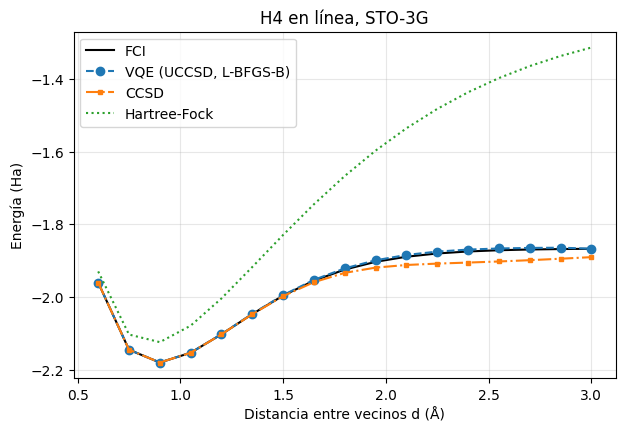

In [11]:
from scipy.sparse.linalg import expm_multiply

estimador = StatevectorEstimator()

def generadores_anti_hermiticos(m):
    """Matrices dispersas A_k = T - T† de cada salto, en el mismo orden que los ángulos del ansatz."""
    n_qubits = 2 * m["norb"]
    a = [destruccion_jordan_wigner(p, n_qubits) for p in range(n_qubits)]
    matrices = []
    for desde, hacia in saltos_posibles(m):
        T = SparsePauliOp("I" * n_qubits)
        for p in hacia:
            T = T.dot(a[p].adjoint())
        for p in reversed(desde):
            T = T.dot(a[p])
        matrices.append((T - T.adjoint()).simplify().to_matrix(sparse=True).tocsr())
    return matrices

def energia_y_gradiente(angulos, A, H, psi0):
    """Energía <H> y su gradiente exacto (método adjunto) del estado exp(θn An)...exp(θ1 A1)|HF>."""
    estados = [psi0]
    for th, Ak in zip(angulos, A):
        estados.append(expm_multiply(th * Ak, estados[-1]))
    psi = estados[-1]
    lam = H @ psi
    energia = float(np.vdot(psi, lam).real)
    grad = np.zeros(len(A))
    for k in reversed(range(len(A))):
        grad[k] = 2 * np.vdot(lam, A[k] @ estados[k + 1]).real
        lam = expm_multiply(-angulos[k] * A[k], lam)
    return energia, grad

def correr_vqe(m, angulos_iniciales):
    """Minimiza la energía con L-BFGS-B partiendo de angulos_iniciales."""
    A = generadores_anti_hermiticos(m)
    Hm = m["H"].to_matrix(sparse=True).tocsr()
    psi0 = np.zeros(2 ** (2 * m["norb"]), dtype=complex)
    psi0[int("00110011", 2)] = 1.0
    return minimize(
        energia_y_gradiente, angulos_iniciales, args=(A, Hm, psi0),
        jac=True, method="L-BFGS-B", options={"maxiter": 500, "ftol": 1e-13, "gtol": 1e-8},
    )

resultados_vqe = []
angulos = np.zeros(ansatz_h4.num_parameters)  # Primer punto: arrancamos desde Hartree-Fock

# Barrido de d: los ángulos óptimos de una distancia son el punto de partida de la siguiente
for datos in problemas_h4:
    res = correr_vqe(datos, angulos)
    angulos = res.x

    # Comprobación con StatevectorEstimator sobre el circuito del ansatz
    circuito = ansatz_ucc(datos)
    e_estimador = float(estimador.run([(circuito, datos["H"], res.x)]).result()[0].data.evs)
    np.testing.assert_allclose(e_estimador, res.fun, atol=1e-6, rtol=0)

    # Referencia exacta (FCI) para esta geometría
    e_fci = fci.FCI(datos["hf"]).kernel()[0]
    # Referencia CCSD para esta geometría
    e_ccsd = cc.CCSD(datos["hf"]).run().e_tot
    datos.update(e_vqe=res.fun, e_ccsd=e_ccsd, e_fci=e_fci, params_vqe=res.x)
    resultados_vqe.append({
        "d": datos["d"], "e_vqe": res.fun, "e_hf": datos["e_hf"], "e_fci": e_fci, "e_ccsd": e_ccsd,
        "angulos": res.x, "iteraciones": res.nit,
    })
    print(f"d = {datos['d']:.2f} Å | E_VQE = {res.fun:.8f} Ha | E_CCSD = {e_ccsd:.8f} Ha | E_FCI = {e_fci:.8f} Ha | "
          f"error = {(res.fun - e_fci) * 1000:.4f} mHa | iter = {res.nit}")

d_vqe = np.array([r["d"] for r in resultados_vqe])
e_vqe = np.array([r["e_vqe"] for r in resultados_vqe])
e_hf_arr = np.array([r["e_hf"] for r in resultados_vqe])
e_fci_arr = np.array([r["e_fci"] for r in resultados_vqe])

# Principio variacional: FCI <= VQE <= HF
assert np.all(e_vqe >= e_fci_arr - 1e-8), "VQE quedó por debajo de FCI: algo anda mal"
assert np.all(e_vqe <= e_hf_arr + 1e-8), "VQE quedó por encima de Hartree-Fock"

i_min = int(np.argmin(e_vqe))
Re = d_vqe[i_min]
De = e_vqe[-1] - e_vqe[i_min]
print(f"\nDistancia de equilibrio (mínimo de VQE): Re = {Re:.2f} Å")
print(f"Energía de disociación: De = E_VQE({d_vqe[-1]:.1f} Å) - E_VQE(Re) = {De:.6f} Ha = {De * 27.2114:.3f} eV")

plt.figure(figsize=(7, 4.5))
plt.plot(d_vqe, e_fci_arr, "k-", label="FCI")
plt.plot(d_vqe, e_vqe, "o--", label="VQE (UCCSD, L-BFGS-B)")
plt.plot(d_vqe, [r["e_ccsd"] for r in resultados_vqe], "s-.", ms=3, label="CCSD")
plt.plot(d_vqe, e_hf_arr, ":", label="Hartree-Fock")
plt.xlabel("Distancia entre vecinos d (Å)")
plt.ylabel("Energía (Ha)")
plt.title("H4 en línea, STO-3G")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Implementación de CCSD y FCI.**

Este paso es importante porque acá vamos a ver una comparación directa entre los valores de la energía medida según Hartree-Fock, según CCSD y según FCI. Además, dado que uno de los objetivos es ganarle a CCSD, vamos a medir el error para cada energía medida para cierta distancia, además de comprobar si converge o no. Hay que tener en cuenta que los resultados son aceptables si:


*   Cota variacional: Las energías de VQE y de muestrear y diagonalizar son cotas superiores de la energía exacta. Si dos métodos variacionales dan energías distintas, el que da la energía más baja está más cerca de la respuesta. Hay que tener cuidado, porque no todos los métodos son variacionales.
*   Convergencia: Si aumentamos los recursos (más shots, un subespacio más grande, más capas en el ansatz o una base más grande) y el resultado deja de cambiar, es una buena señal. Si sigue cambiando, todavía no llegamos.




In [12]:
for datos in problemas_h4:
    hf = datos["hf"]
    n_electrones = sum(datos["nelec"])

    # FCI: la respuesta exacta en esta base (diagonaliza el problema completo)
    fci_calc = mcscf.CASCI(hf, datos["norb"], n_electrones)
    datos["e_fci"] = fci_calc.kernel()[0]

    # CCSD: el método clásico al que hay que ganarle en d >= 1,8 Å
    ccsd = cc.CCSD(hf).run()
    datos["e_ccsd"] = ccsd.e_tot
    datos["ccsd_convergio"] = ccsd.converged

print(f"{'d (Å)':>6} | {'E_HF':>12} | {'E_CCSD':>12} | {'E_FCI':>12} | {'err CCSD (mHa)':>14} | CCSD convergió")
for datos in problemas_h4:
    err_ccsd = (datos["e_ccsd"] - datos["e_fci"]) * 1000
    print(f"{datos['d']:6.2f} | {datos['e_hf']:12.6f} | {datos['e_ccsd']:12.6f} | "
          f"{datos['e_fci']:12.6f} | {err_ccsd:14.2f} | {datos['ccsd_convergio']}")

 d (Å) |         E_HF |       E_CCSD |        E_FCI | err CCSD (mHa) | CCSD convergió
  0.60 |    -1.929564 |    -1.960189 |    -1.960194 |           0.00 | True
  0.75 |    -2.103291 |    -2.145106 |    -2.145111 |           0.00 | True
  0.90 |    -2.124260 |    -2.180309 |    -2.180317 |           0.01 | True
  1.05 |    -2.078863 |    -2.153436 |    -2.153441 |           0.00 | True
  1.20 |    -2.003867 |    -2.102671 |    -2.102608 |          -0.06 | True
  1.35 |    -1.917342 |    -2.047241 |    -2.046846 |          -0.39 | True
  1.50 |    -1.829137 |    -1.997624 |    -1.996150 |          -1.47 | True
  1.65 |    -1.744686 |    -1.959165 |    -1.955033 |          -4.13 | True
  1.80 |    -1.666867 |    -1.933537 |    -1.924431 |          -9.11 | True
  1.95 |    -1.597033 |    -1.919084 |    -1.903154 |         -15.93 | True
  2.10 |    -1.535569 |    -1.911864 |    -1.889115 |         -22.75 | True
  2.25 |    -1.482243 |    -1.908045 |    -1.880189 |         -27.86 | True
  

Viendo los resultados de arriba, podemos observar que a medida que aumenta la distancia, mayor valor tiene la energía medida por Hartree-Fock. Vemos que con CCSD, la energía también aumenta con la distancia pero de forma mucho más chica que por Hatree-Fock. Es como más "rebelde", en ese sentido. Algo similar sucede con FCI, pero esto se observa más en CCSD. No obstante, el error es más grande a medida que aumentamos la distancia entre núcleos.

También, hacemos un chequeo súper primitivo. Compararemos nuestros resultados eon la energía exacta de FCI, aunque se sabe que la idea es ver dónde FCI es imposible de calcular

In [13]:
# El Hamiltoniano de qubits tiene que reproducir FCI =====
# Ojo: la matriz de 8 qubits incluye estados con cualquier cantidad de electrones (0 a 8).
# Hay que quedarse solo con los que tienen 2 electrones alfa (qubits 0-3) y 2 beta (qubits 4-7).
indices_validos = [k for k in range(2**8)
                   if bin(k & 0b00001111).count("1") == 2 and bin(k >> 4).count("1") == 2]

for datos in problemas_h4:
    matriz = datos["H"].to_matrix()
    sub = matriz[np.ix_(indices_validos, indices_validos)]
    e_min_qubits = np.linalg.eigvalsh(sub)[0]
    np.testing.assert_allclose(e_min_qubits, datos["e_fci"], atol=1e-8, rtol=0)

print(f"Chequeo OK: en los {len(indices_validos)} estados con 2+2 electrones, "
      "el autovalor más chico coincide con FCI en todas las distancias.")

Chequeo OK: en los 36 estados con 2+2 electrones, el autovalor más chico coincide con FCI en todas las distancias.


Optimización de los parámetros (ángulos)

In [14]:
import time
def preparar_vqe_rapido(datos, capas=1):
    """Arma las matrices que necesita el VQE rápido para una distancia."""
    norb = datos["norb"]
    n_qubits = 2 * norb
    a = [destruccion_jordan_wigner(p, n_qubits) for p in range(n_qubits)]
    generadores = []
    for desde, hacia in saltos_posibles(datos):           # mismo orden que los ángulos del ansatz
        T = SparsePauliOp("I" * n_qubits)
        for p in hacia:
            T = T.dot(a[p].adjoint())
        for p in reversed(desde):
            T = T.dot(a[p])
        A = (T - T.adjoint()).simplify().to_matrix(sparse=True).real.tocsr()   # A = T - T†
        generadores.append((A, (A @ A).tocsr()))
    H = datos["H"].to_matrix(sparse=True).real.tocsr()
    n_alfa, n_beta = datos["nelec"]
    psi_hf = np.zeros(2 ** n_qubits)
    psi_hf[sum(1 << i for i in range(n_alfa)) + sum(1 << (norb + i) for i in range(n_beta))] = 1.0
    return H, generadores * capas, psi_hf          # con 2 capas, la lista de saltos se repite


def energia_y_gradiente(angulos, H, generadores, psi_hf):
    """Energía <psi|H|psi> y su gradiente exacto respecto de los ángulos.

    Cada compuerta del ansatz es U = exp(θA) = I + sen(θ)·A + (1 - cos(θ))·A²
    (vale porque A³ = -A para los saltos de electrones), así que se aplica con dos
    multiplicaciones de matrices ralas, sin aproximaciones.
    """
    # Hacia adelante: aplicamos las compuertas una por una
    psi = psi_hf.copy()
    for (A, A2), t in zip(generadores, angulos):
        psi = psi + np.sin(t) * (A @ psi) + (1 - np.cos(t)) * (A2 @ psi)
    lam = H @ psi
    energia = psi @ lam
    # Hacia atrás: deshacemos cada compuerta y calculamos su derivada (método adjunto)
    grad = np.zeros(len(angulos))
    for k in reversed(range(len(angulos))):
        A, A2 = generadores[k]
        t = angulos[k]
        # deshacer U_k: U(-θ) = I - sen(θ)·A + (1 - cos(θ))·A²
        psi = psi - np.sin(t) * (A @ psi) + (1 - np.cos(t)) * (A2 @ psi)
        grad[k] = 2 * lam @ (np.cos(t) * (A @ psi) + np.sin(t) * (A2 @ psi))
        lam = lam - np.sin(t) * (A @ lam) + (1 - np.cos(t)) * (A2 @ lam)
    return energia, grad


def vqe_rapido(datos, x0, capas=1):
    H, generadores, psi_hf = preparar_vqe_rapido(datos, capas)
    return minimize(energia_y_gradiente, x0, args=(H, generadores, psi_hf),
                    jac=True, method="L-BFGS-B", options={"maxiter": 2000, "gtol": 1e-10})


CAPAS = 2                     # 1 = UCCSD del curso (26 ángulos, 292 CZ); 2 = dos capas (52 ángulos, 582 CZ)
n_angulos = 26 * CAPAS
rng = np.random.default_rng(0)

angulos_previos = np.zeros(n_angulos)
for datos in problemas_h4:
    t0 = time.time()
    arranques = [np.zeros(n_angulos), angulos_previos] + [rng.normal(0, 0.1, n_angulos) for _ in range(3)]
    candidatos = [vqe_rapido(datos, x0, CAPAS) for x0 in arranques]
    mejor = min(candidatos, key=lambda r: r.fun)          # principio variacional: la más baja gana
    datos["angulos_opt"] = mejor.x
    datos["e_vqe_sin_ruido"] = mejor.fun
    angulos_previos = mejor.x
    print(f"d = {datos['d']:.2f} Å | E = {mejor.fun:.8f} Ha | error vs FCI = "
          f"{(mejor.fun - datos['e_fci']) * 1000:7.3f} mHa | {time.time() - t0:.1f} s")

d = 0.60 Å | E = -1.96019267 Ha | error vs FCI =   0.001 mHa | 1.5 s
d = 0.75 Å | E = -2.14510905 Ha | error vs FCI =   0.002 mHa | 2.3 s
d = 0.90 Å | E = -2.18031504 Ha | error vs FCI =   0.002 mHa | 4.5 s
d = 1.05 Å | E = -2.15343662 Ha | error vs FCI =   0.004 mHa | 3.0 s
d = 1.20 Å | E = -2.10260808 Ha | error vs FCI =   0.000 mHa | 5.6 s
d = 1.35 Å | E = -2.04684635 Ha | error vs FCI =   0.000 mHa | 8.4 s
d = 1.50 Å | E = -1.99615032 Ha | error vs FCI =   0.000 mHa | 4.8 s
d = 1.65 Å | E = -1.95503341 Ha | error vs FCI =   0.000 mHa | 6.5 s
d = 1.80 Å | E = -1.92443063 Ha | error vs FCI =   0.000 mHa | 3.8 s
d = 1.95 Å | E = -1.90315442 Ha | error vs FCI =   0.000 mHa | 3.9 s
d = 2.10 Å | E = -1.88911487 Ha | error vs FCI =   0.000 mHa | 7.2 s
d = 2.25 Å | E = -1.88018866 Ha | error vs FCI =   0.000 mHa | 5.0 s
d = 2.40 Å | E = -1.87465157 Ha | error vs FCI =   0.000 mHa | 8.5 s
d = 2.55 Å | E = -1.87127113 Ha | error vs FCI =   0.000 mHa | 6.9 s
d = 2.70 Å | E = -1.86923065 Ha | 

In [15]:
# ===== Ansatz UCCSD con varias capas (repite los 26 saltos, cada vez con ángulos nuevos) =====
def ansatz_ucc_capas(m, capas=2):
    norb = m["norb"]
    n_alfa, n_beta = m["nelec"]
    n_qubits = 2 * norb
    a = [destruccion_jordan_wigner(p, n_qubits) for p in range(n_qubits)]
    saltos = saltos_posibles(m) * capas                  # la lista de saltos repetida
    theta = ParameterVector("θ", len(saltos))
    circuito = QuantumCircuit(n_qubits)
    for i in range(n_alfa):
        circuito.x(i)
    for i in range(n_beta):
        circuito.x(norb + i)
    for angulo, (desde, hacia) in zip(theta, saltos):
        T = SparsePauliOp("I" * n_qubits)
        for p in hacia:
            T = T.dot(a[p].adjoint())
        for p in reversed(desde):
            T = T.dot(a[p])
        G = (1j * (T - T.adjoint())).simplify()
        circuito.append(PauliEvolutionGate(G, time=angulo), range(n_qubits))
    return transpile(circuito, basis_gates=["cz", "rz", "sx", "x"], optimization_level=3)

In [16]:
# ===== Chequeo: el circuito real da la misma energía que el cálculo rápido =====
# Es la garantía de que los ángulos sirven para el circuito que después medimos con shots (paso 6).
ansatz_cz = ansatz_ucc_capas(problemas_h4[0], CAPAS)
print("Parámetros:", ansatz_cz.num_parameters, "| CZ:", ansatz_cz.count_ops().get("cz", 0))

estimador_exacto = StatevectorEstimator()
for datos in problemas_h4[::4]:
    e_circuito = float(estimador_exacto.run([(ansatz_cz, datos["H"], datos["angulos_opt"])]).result()[0].data.evs)
    diferencia = (e_circuito - datos["e_vqe_sin_ruido"]) * 1000
    assert abs(diferencia) < 1e-6, f"No coinciden en d = {datos['d']}"
    print(f"d = {datos['d']:.2f} Å | circuito vs cálculo rápido: {diferencia:.1e} mHa")
print("Chequeo OK")

Parámetros: 52 | CZ: 582
d = 0.60 Å | circuito vs cálculo rápido: -2.4e-11 mHa
d = 1.20 Å | circuito vs cálculo rápido: -3.5e-11 mHa
d = 1.80 Å | circuito vs cálculo rápido: -2.5e-11 mHa
d = 2.40 Å | circuito vs cálculo rápido: -2.9e-11 mHa
d = 3.00 Å | circuito vs cálculo rápido: -2.2e-11 mHa
Chequeo OK


¿Qué pasa si CAPAS = 1? Es decir, qué pasa si es una sola capa de rotación

In [17]:
def preparar_vqe_rapido(datos, capas=1):
    """Arma las matrices que necesita el VQE rápido para una distancia."""
    norb = datos["norb"]
    n_qubits = 2 * norb
    a = [destruccion_jordan_wigner(p, n_qubits) for p in range(n_qubits)]
    generadores = []
    for desde, hacia in saltos_posibles(datos):           # mismo orden que los ángulos del ansatz
        T = SparsePauliOp("I" * n_qubits)
        for p in hacia:
            T = T.dot(a[p].adjoint())
        for p in reversed(desde):
            T = T.dot(a[p])
        A = (T - T.adjoint()).simplify().to_matrix(sparse=True).real.tocsr()   # A = T - T†
        generadores.append((A, (A @ A).tocsr()))
    H = datos["H"].to_matrix(sparse=True).real.tocsr()
    n_alfa, n_beta = datos["nelec"]
    psi_hf = np.zeros(2 ** n_qubits)
    psi_hf[sum(1 << i for i in range(n_alfa)) + sum(1 << (norb + i) for i in range(n_beta))] = 1.0
    return H, generadores * capas, psi_hf          # con 2 capas, la lista de saltos se repite


def energia_y_gradiente(angulos, H, generadores, psi_hf):
    """Energía <psi|H|psi> y su gradiente exacto respecto de los ángulos.

    Cada compuerta del ansatz es U = exp(θA) = I + sen(θ)·A + (1 - cos(θ))·A²
    (vale porque A³ = -A para los saltos de electrones), así que se aplica con dos
    multiplicaciones de matrices ralas, sin aproximaciones.
    """
    # Hacia adelante: aplicamos las compuertas una por una
    psi = psi_hf.copy()
    for (A, A2), t in zip(generadores, angulos):
        psi = psi + np.sin(t) * (A @ psi) + (1 - np.cos(t)) * (A2 @ psi)
    lam = H @ psi
    energia = psi @ lam
    # Hacia atrás: deshacemos cada compuerta y calculamos su derivada (método adjunto)
    grad = np.zeros(len(angulos))
    for k in reversed(range(len(angulos))):
        A, A2 = generadores[k]
        t = angulos[k]
        # deshacer U_k: U(-θ) = I - sen(θ)·A + (1 - cos(θ))·A²
        psi = psi - np.sin(t) * (A @ psi) + (1 - np.cos(t)) * (A2 @ psi)
        grad[k] = 2 * lam @ (np.cos(t) * (A @ psi) + np.sin(t) * (A2 @ psi))
        lam = lam - np.sin(t) * (A @ lam) + (1 - np.cos(t)) * (A2 @ lam)
    return energia, grad


def vqe_rapido(datos, x0, capas=1):
    H, generadores, psi_hf = preparar_vqe_rapido(datos, capas)
    return minimize(energia_y_gradiente, x0, args=(H, generadores, psi_hf),
                    jac=True, method="L-BFGS-B", options={"maxiter": 2000, "gtol": 1e-10})


CAPAS = 1                     # 1 = UCCSD del curso (26 ángulos, 292 CZ); 2 = dos capas (52 ángulos, 582 CZ)
n_angulos = 26 * CAPAS
rng = np.random.default_rng(0)

angulos_previos = np.zeros(n_angulos)
for datos in problemas_h4:
    t0 = time.time()
    arranques = [np.zeros(n_angulos), angulos_previos] + [rng.normal(0, 0.1, n_angulos) for _ in range(3)]
    candidatos = [vqe_rapido(datos, x0, CAPAS) for x0 in arranques]
    mejor = min(candidatos, key=lambda r: r.fun)          # principio variacional: la más baja gana
    datos["angulos_opt"] = mejor.x
    datos["e_vqe_sin_ruido"] = mejor.fun
    angulos_previos = mejor.x
    print(f"d = {datos['d']:.2f} Å | E = {mejor.fun:.8f} Ha | error vs FCI = "
          f"{(mejor.fun - datos['e_fci']) * 1000:7.3f} mHa | {time.time() - t0:.1f} s")

d = 0.60 Å | E = -1.96018780 Ha | error vs FCI =   0.006 mHa | 0.5 s
d = 0.75 Å | E = -2.14510091 Ha | error vs FCI =   0.010 mHa | 0.5 s
d = 0.90 Å | E = -2.18028194 Ha | error vs FCI =   0.035 mHa | 0.5 s
d = 1.05 Å | E = -2.15332490 Ha | error vs FCI =   0.116 mHa | 0.5 s
d = 1.20 Å | E = -2.10229358 Ha | error vs FCI =   0.315 mHa | 0.5 s
d = 1.35 Å | E = -2.04613487 Ha | error vs FCI =   0.711 mHa | 0.5 s
d = 1.50 Å | E = -1.99478317 Ha | error vs FCI =   1.367 mHa | 0.6 s
d = 1.65 Å | E = -1.95277032 Ha | error vs FCI =   2.263 mHa | 0.6 s
d = 1.80 Å | E = -1.92115689 Ha | error vs FCI =   3.274 mHa | 0.7 s
d = 1.95 Å | E = -1.89895029 Ha | error vs FCI =   4.204 mHa | 0.7 s
d = 2.10 Å | E = -1.88513971 Ha | error vs FCI =   3.975 mHa | 0.9 s
d = 2.25 Å | E = -1.87749858 Ha | error vs FCI =   2.690 mHa | 0.9 s
d = 2.40 Å | E = -1.87288268 Ha | error vs FCI =   1.769 mHa | 1.2 s
d = 2.55 Å | E = -1.87011470 Ha | error vs FCI =   1.156 mHa | 1.7 s
d = 2.70 Å | E = -1.86847646 Ha | 

Como corrimos las dos optimizaciones sobre el mismo problemas_h4 y ambas escribieron datos["angulos_opt"], la última corrida sobrescribió la anterior. Para conservar ambas, cambiamos las asignaciones de la celda de optimización por estas y corremos cada configuración que nos falte

In [18]:
datos.setdefault("opt_por_capas", {})[CAPAS] = {
    "angulos": mejor.x.copy(),
    "energia_sin_ruido": float(mejor.fun),
}

Medición de la energía con shots. Acá es obtener la energía tal como la mediría una computadora cuántica: con shots y barra de error. Usamos SamplerV2 porque hace shots de verdad.

In [19]:
import numpy as np
from qiskit_aer.primitives import SamplerV2 as AerSampler


def preparar_mediciones(circuito_fijo, H):
    """Devuelve la constante y un circuito de medición por grupo de Pauli."""
    constante = 0.0
    grupos = []

    for grupo in H.group_commuting(qubit_wise=True):
        bases = {}
        terminos = []

        for etiqueta, coef in grupo.to_list():
            coef = float(coef.real)
            mascara = 0

            # En una etiqueta de Qiskit, el qubit 0 está a la derecha.
            for qubit, pauli in enumerate(reversed(etiqueta)):
                if pauli != "I":
                    bases[qubit] = pauli
                    mascara |= 1 << qubit

            if mascara == 0:
                constante += coef
            else:
                terminos.append((mascara, coef))

        if not terminos:
            continue

        circuito = circuito_fijo.copy()
        for qubit, base in bases.items():
            if base == "X":
                circuito.h(qubit)
            elif base == "Y":
                circuito.sdg(qubit)
                circuito.h(qubit)

        circuito.measure_all()
        grupos.append((circuito, terminos))

    return constante, grupos


def estadisticas_grupo(cuentas, terminos):
    """Calcula la media y la varianza muestral del aporte de un grupo."""
    aportes = []
    frecuencias = []

    for bitstring, frecuencia in cuentas.items():
        bits = int(bitstring, 2)
        aporte = sum(
            coef * (-1) ** ((bits & mascara).bit_count() % 2)
            for mascara, coef in terminos
        )
        aportes.append(aporte)
        frecuencias.append(frecuencia)

    aportes = np.asarray(aportes)
    frecuencias = np.asarray(frecuencias)
    n = frecuencias.sum()

    media = np.dot(frecuencias, aportes) / n
    varianza = np.dot(frecuencias, (aportes - media) ** 2) / (n - 1)
    return media, varianza


def muestrear_grupos(grupos, shots_por_grupo, semilla):
    sampler = AerSampler(seed=semilla)
    pubs = [
        (circuito, None, int(shots))
        for (circuito, _), shots in zip(grupos, shots_por_grupo)
    ]
    resultados = sampler.run(pubs).result()

    return np.asarray([
        estadisticas_grupo(resultado.data.meas.get_counts(), terminos)
        for resultado, (_, terminos) in zip(resultados, grupos)
    ])


def medir_energia(circuito_fijo, H, shots_totales, shots_piloto=4_000, semilla=0):
    """Mide E y sigma en Ha. El presupuesto incluye la corrida piloto."""
    constante, grupos = preparar_mediciones(circuito_fijo, H)
    n_grupos = len(grupos)

    # Dejamos un mínimo final por grupo, incluso si su varianza piloto fue cero.
    minimo_final = 100
    costo_piloto = n_grupos * shots_piloto
    restantes = shots_totales - costo_piloto - n_grupos * minimo_final
    if shots_piloto < 2 or restantes < 0:
        raise ValueError("Presupuesto insuficiente para el piloto y la medición final.")

    piloto = muestrear_grupos(grupos, [shots_piloto] * n_grupos, semilla)
    pesos = np.sqrt(piloto[:, 1])
    if pesos.sum() == 0:
        pesos = np.ones(n_grupos)

    # Para un presupuesto fijo, asignamos más shots a los grupos más variables.
    cuotas = restantes * pesos / pesos.sum()
    extras = np.floor(cuotas).astype(int)
    sobrantes = restantes - extras.sum()
    orden = np.argsort(-(cuotas - extras))
    extras[orden[:sobrantes]] += 1
    shots_finales = minimo_final + extras

    # Una muestra independiente para calcular la energía y su barra de error.
    final = muestrear_grupos(grupos, shots_finales, semilla + 1)
    energia = constante + final[:, 0].sum()
    sigma = np.sqrt(np.sum(final[:, 1] / shots_finales))

    return {
        "energia": float(energia),
        "sigma": float(sigma),
        "grupos": n_grupos,
        "shots_piloto": costo_piloto,
        "shots_medicion": int(shots_finales.sum()),
        "shots_totales": int(costo_piloto + shots_finales.sum()),
    }

In [20]:
datos = min(problemas_h4, key=lambda punto: abs(punto["d"] - 2.4))

angulos = datos["angulos_opt"]
capas = len(angulos) // len(saltos_posibles(datos))

ansatz = ansatz_ucc_capas(datos, capas=capas)
circuito_fijo = ansatz.assign_parameters(angulos)

medicion = medir_energia(
    circuito_fijo,
    datos["H"],
    shots_totales=2_000_000,
    semilla=100,
)

print(f"d = {datos['d']:.2f} Å | capas = {capas}")
print(f"E = {medicion['energia']:.8f} Ha")
print(f"σ = {1000 * medicion['sigma']:.3f} mHa")
print(f"Shots: {medicion['shots_totales']:,}")
print(f"CZ: {ansatz.count_ops().get('cz', 0)}")

d = 2.40 Å | capas = 1
E = -1.87136558 Ha
σ = 1.405 mHa
Shots: 2,000,000
CZ: 292


In [21]:
# Guardamos la medición de prueba para aprovechar esos shots.
datos["medicion_vqe"] = {
    **medicion,
    "capas": capas,
    "cz": ansatz.count_ops().get("cz", 0),
}

# Reutilizamos el mismo ansatz y cambiamos los ángulos en cada distancia.
for i, punto in enumerate(problemas_h4):
    if "medicion_vqe" not in punto:
        circuito_fijo = ansatz.assign_parameters(punto["angulos_opt"])
        punto["medicion_vqe"] = {
            **medir_energia(
                circuito_fijo,
                punto["H"],
                shots_totales=2_000_000,
                semilla=1_000 + 2 * i,
            ),
            "capas": capas,
            "cz": ansatz.count_ops().get("cz", 0),
        }

    medida = punto["medicion_vqe"]
    delta_mha = 1_000 * (medida["energia"] - punto["e_vqe_sin_ruido"])
    sigma_mha = 1_000 * medida["sigma"]

    print(
        f"d = {punto['d']:.2f} Å | E = {medida['energia']:.8f} Ha | "
        f"σ = {sigma_mha:.3f} mHa | Δ sin ruido = {delta_mha:+.3f} mHa"
    )

d = 0.60 Å | E = -1.96163898 Ha | σ = 1.615 mHa | Δ sin ruido = -1.451 mHa
d = 0.75 Å | E = -2.14537082 Ha | σ = 1.576 mHa | Δ sin ruido = -0.270 mHa
d = 0.90 Å | E = -2.18090948 Ha | σ = 1.556 mHa | Δ sin ruido = -0.628 mHa
d = 1.05 Å | E = -2.14985820 Ha | σ = 1.558 mHa | Δ sin ruido = +3.467 mHa
d = 1.20 Å | E = -2.10434212 Ha | σ = 1.560 mHa | Δ sin ruido = -2.049 mHa
d = 1.35 Å | E = -2.04586847 Ha | σ = 1.562 mHa | Δ sin ruido = +0.266 mHa
d = 1.50 Å | E = -1.99829019 Ha | σ = 1.550 mHa | Δ sin ruido = -3.507 mHa
d = 1.65 Å | E = -1.95294057 Ha | σ = 1.527 mHa | Δ sin ruido = -0.170 mHa
d = 1.80 Å | E = -1.92237364 Ha | σ = 1.494 mHa | Δ sin ruido = -1.217 mHa
d = 1.95 Å | E = -1.89997795 Ha | σ = 1.459 mHa | Δ sin ruido = -1.028 mHa
d = 2.10 Å | E = -1.88569357 Ha | σ = 1.450 mHa | Δ sin ruido = -0.554 mHa
d = 2.25 Å | E = -1.87926470 Ha | σ = 1.424 mHa | Δ sin ruido = -1.766 mHa
d = 2.40 Å | E = -1.87136558 Ha | σ = 1.405 mHa | Δ sin ruido = +1.517 mHa
d = 2.55 Å | E = -1.87207

Con la grilla completa, el siguiente paso es graficar la energía medida con sus barras +-σ, superponer CCSD y FCI y sacar \(R_e\) y \(D_e\) de la curva VQE.

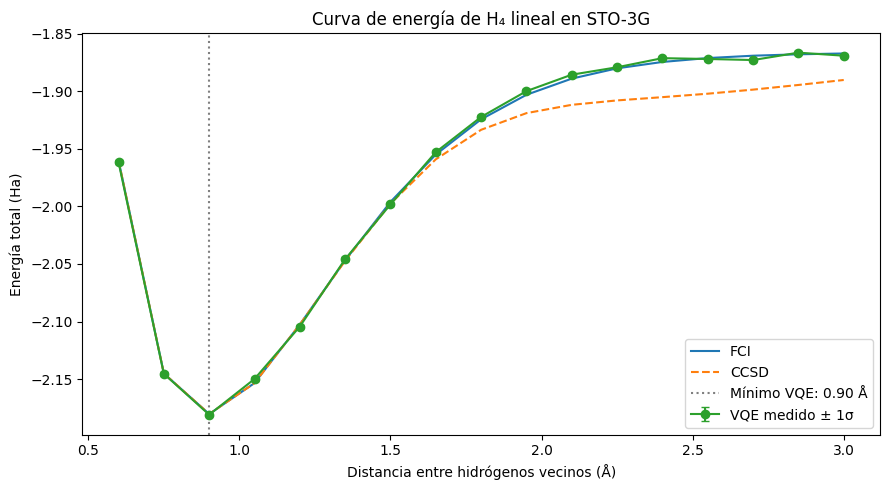

Distancia de equilibrio en la grilla: 0.90 Å
Energía de disociación: 0.311684 Ha (311.68 mHa)


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from pyscf import cc, fci

puntos = sorted(problemas_h4, key=lambda punto: punto["d"])

for punto in puntos:
    if "e_fci" not in punto:
        punto["e_fci"] = fci.FCI(punto["hf"]).kernel()[0]

    if "ccsd_convergio" not in punto:
        calculo_ccsd = cc.CCSD(punto["hf"]).run()
        punto["e_ccsd"] = calculo_ccsd.e_tot
        punto["ccsd_convergio"] = calculo_ccsd.converged

d = np.array([p["d"] for p in puntos])
e_vqe = np.array([p["medicion_vqe"]["energia"] for p in puntos])
sigma = np.array([p["medicion_vqe"]["sigma"] for p in puntos])
e_fci = np.array([p["e_fci"] for p in puntos])
e_ccsd = np.array([p["e_ccsd"] for p in puntos])
ccsd_ok = np.array([p["ccsd_convergio"] for p in puntos])

# Estimación de R_e a partir del mínimo medido en la grilla.
i_min = np.argmin(e_vqe)
i_final = np.flatnonzero(np.isclose(d, 3.0)).item()

r_e = d[i_min]
d_e = e_vqe[i_final] - e_vqe[i_min]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(d, e_fci, "-", label="FCI")
ax.plot(d, np.where(ccsd_ok, e_ccsd, np.nan), "--", label="CCSD")
ax.errorbar(d, e_vqe, yerr=sigma, fmt="o-", capsize=3,
            label="VQE medido ± 1σ")
ax.axvline(r_e, color="gray", linestyle=":", label=f"Mínimo VQE: {r_e:.2f} Å")
ax.set(
    xlabel="Distancia entre hidrógenos vecinos (Å)",
    ylabel="Energía total (Ha)",
    title="Curva de energía de H₄ lineal en STO-3G",
)
ax.legend()
fig.tight_layout()
plt.show()

print(f"Distancia de equilibrio en la grilla: {r_e:.2f} Å")
print(f"Energía de disociación: {d_e:.6f} Ha ({1000 * d_e:.2f} mHa)")

if not ccsd_ok.all():
    print("CCSD no convergió en estas distancias (Å):", d[~ccsd_ok])

In [23]:
error_vqe = 1000 * np.abs(e_vqe - e_fci)
error_ccsd = 1000 * np.abs(e_ccsd - e_fci)
sigma_mha = 1000 * sigma

print("d (Å) | Error VQE + σ | Error CCSD | ¿Supera CCSD? | ¿Precisión química?")
for i in np.flatnonzero(d >= 1.8 - 1e-9):
    error_con_sigma = error_vqe[i] + sigma_mha[i]
    supera = "Sí" if error_con_sigma < error_ccsd[i] else "No"
    referencia_ccsd = f"{error_ccsd[i]:.3f} mHa"

    if not ccsd_ok[i]:
        supera = "Sin evaluar"
        referencia_ccsd = "Sin converger"

    precision = "Sí" if error_vqe[i] < 1.6 else "No"

    print(
        f"{d[i]:.2f} | {error_con_sigma:.3f} mHa | "
        f"{referencia_ccsd} | {supera} | {precision}"
    )

d (Å) | Error VQE + σ | Error CCSD | ¿Supera CCSD? | ¿Precisión química?
1.80 | 3.551 mHa | 9.107 mHa | Sí | No
1.95 | 4.635 mHa | 15.929 mHa | Sí | No
2.10 | 4.871 mHa | 22.749 mHa | Sí | No
2.25 | 2.347 mHa | 27.857 mHa | Sí | Sí
2.40 | 4.691 mHa | 30.560 mHa | Sí | No
2.55 | 2.183 mHa | 30.943 mHa | Sí | Sí
2.70 | 5.124 mHa | 29.445 mHa | Sí | No
2.85 | 2.779 mHa | 26.619 mHa | Sí | Sí
3.00 | 3.257 mHa | 23.013 mHa | Sí | No


El VQE superó a CCSD en los nueve puntos evaluados entre 1,80 y 3,00 Å. En todos ellos, el error absoluto de VQE respecto de FCI, incluso después de sumarle una incertidumbre estadística σ, fue menor que el error absoluto de CCSD. El margen más ajustado se obtuvo a 1,80 Å, donde el error de VQE más σ fue de 3,155 mHa, frente a 9,107 mHa de CCSD.

La precisión química se alcanzó en tres de los nueve puntos, a 1,95 , 2,55 y 2,85 Å. En esas distancias, la estimación central de VQE quedó a menos de 1,6 mHa de FCI. Así, el resultado cumplió el objetivo principal en toda la grilla de la zona estirada y alcanzó la meta de precisión química en tres geometrías.

En la cadena estirada, varias configuraciones electrónicas adquieren peso y una descripción basada en una sola referencia de Hartree–Fock se vuelve más exigente. En este experimento, el circuito optimizado con VQE dio energías más cercanas a FCI que CCSD en todas las distancias estiradas que evaluamos para H4 en la base STO‑3G.

Ahora, vamos a efectuar la tabla de resultados

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

filas = []

for punto in sorted(problemas_h4, key=lambda p: p["d"]):
    medida = punto["medicion_vqe"]
    d = punto["d"]
    e_vqe = medida["energia"]
    e_fci = punto["e_fci"]
    ccsd_ok = punto["ccsd_convergio"]
    e_ccsd = punto["e_ccsd"] if ccsd_ok else np.nan

    error_vqe = 1000 * abs(e_vqe - e_fci)
    error_ccsd = 1000 * abs(e_ccsd - e_fci)
    sigma_mha = 1000 * medida["sigma"]
    en_zona_estirada = d >= 1.8 - 1e-9

    assert medida["shots_totales"] == (
        medida["shots_piloto"] + medida["shots_medicion"]
    ), f"El total de shots no coincide para d = {d:.2f} Å"

    supera = (
        "Sí" if error_vqe + sigma_mha < error_ccsd else "No"
    ) if en_zona_estirada and ccsd_ok else "—"

    filas.append({
        "d (Å)": d,
        "E VQE (Ha)": e_vqe,
        "E FCI (Ha)": e_fci,
        "E CCSD (Ha)": e_ccsd,
        "σ (mHa)": sigma_mha,
        "Error VQE (mHa)": error_vqe,
        "Error VQE + σ (mHa)": error_vqe + sigma_mha,
        "Error CCSD (mHa)": error_ccsd,
        "Shots piloto": medida["shots_piloto"],
        "Shots medición": medida["shots_medicion"],
        "Shots totales": medida["shots_totales"],
        "CZ": medida["cz"],
        "Capas": medida["capas"],
        "CCSD convergió": ccsd_ok,
        "Supera CCSD": supera,
        "Precisión química": "Sí" if error_vqe < 1.6 else "No",
    })

tabla = pd.DataFrame(filas)

formatos = {col: "{:.8f}" for col in tabla if col.endswith("(Ha)")}
formatos.update({col: "{:.3f}" for col in tabla if col.endswith("(mHa)")})
formatos.update({col: "{:,d}" for col in tabla if col.startswith("Shots")})
formatos["d (Å)"] = "{:.2f}"

display(tabla.style.format(formatos, na_rep="—"))

,d (Å),E VQE (Ha),E FCI (Ha),E CCSD (Ha),σ (mHa),Error VQE (mHa),Error VQE + σ (mHa),Error CCSD (mHa),Shots piloto,Shots medición,Shots totales,CZ,Capas,CCSD convergió,Supera CCSD,Precisión química
0,0.60,-1.96163898,-1.96019364,-1.96018888,1.615,1.445,3.060,0.005,"184,000","1,816,000","2,000,000",292,1,True,—,Sí
1,0.75,-2.14537082,-2.14511065,-2.14510625,1.576,0.260,1.836,0.004,"184,000","1,816,000","2,000,000",292,1,True,—,Sí
2,0.90,-2.18090948,-2.18031661,-2.18030941,1.556,0.593,2.149,0.007,"184,000","1,816,000","2,000,000",292,1,True,—,Sí
3,1.05,-2.14985820,-2.15344103,-2.15343649,1.558,3.583,5.141,0.005,"184,000","1,816,000","2,000,000",292,1,True,—,No
4,1.20,-2.10434212,-2.10260848,-2.10267114,1.560,1.734,3.294,0.063,"184,000","1,816,000","2,000,000",292,1,True,—,No
5,1.35,-2.04586847,-2.04684635,-2.04724078,1.562,0.978,2.540,0.394,"184,000","1,816,000","2,000,000",292,1,True,—,Sí
6,1.50,-1.99829019,-1.99615033,-1.99762405,1.550,2.140,3.690,1.474,"184,000","1,816,000","2,000,000",292,1,True,—,No
7,1.65,-1.95294057,-1.95503342,-1.95916481,1.527,2.093,3.620,4.131,"184,000","1,816,000","2,000,000",292,1,True,—,No
8,1.80,-1.92237364,-1.92443064,-1.93353718,1.494,2.057,3.551,9.107,"184,000","1,816,000","2,000,000",292,1,True,Sí,No
9,1.95,-1.89997795,-1.90315443,-1.91908373,1.459,3.176,4.635,15.929,"184,000","1,816,000","2,000,000",292,1,True,Sí,No


**Curva de energía y errores**

El primer gráfico muestra la curva física. El segundo muestra por separado el error central y el criterio con σ, con una línea horizontal en 1,6 mHa.

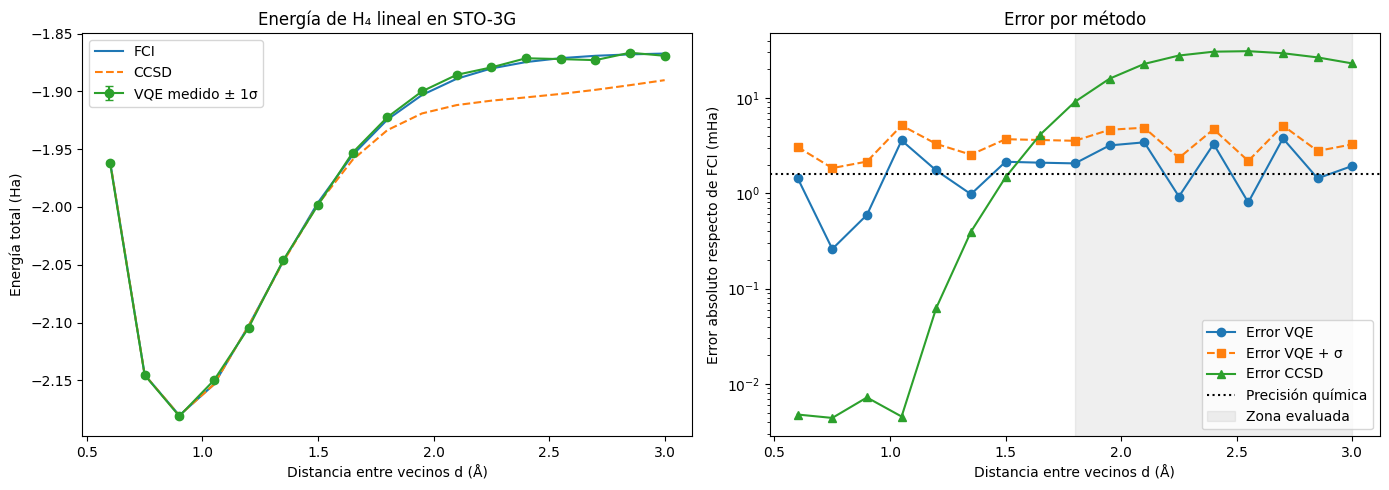

In [25]:
d = tabla["d (Å)"].to_numpy()
e_vqe = tabla["E VQE (Ha)"].to_numpy()
sigma = tabla["σ (mHa)"].to_numpy() / 1000

fig, (ax_e, ax_err) = plt.subplots(1, 2, figsize=(14, 5))

ax_e.plot(d, tabla["E FCI (Ha)"], label="FCI")
ax_e.plot(d, tabla["E CCSD (Ha)"], "--", label="CCSD")
ax_e.errorbar(d, e_vqe, yerr=sigma, fmt="o-", capsize=3,
              label="VQE medido ± 1σ")
ax_e.set(
    xlabel="Distancia entre vecinos d (Å)",
    ylabel="Energía total (Ha)",
    title="Energía de H₄ lineal en STO-3G",
)
ax_e.legend()

for columna, estilo, etiqueta in [
    ("Error VQE (mHa)", "o-", "Error VQE"),
    ("Error VQE + σ (mHa)", "s--", "Error VQE + σ"),
    ("Error CCSD (mHa)", "^-", "Error CCSD"),
]:
    valores = tabla[columna].to_numpy()
    ax_err.plot(d, np.where(valores > 0, valores, np.nan), estilo, label=etiqueta)

ax_err.axhline(1.6, color="black", linestyle=":", label="Precisión química")
ax_err.axvspan(1.8, 3.0, color="gray", alpha=0.12, label="Zona evaluada")
ax_err.set(
    xlabel="Distancia entre vecinos d (Å)",
    ylabel="Error absoluto respecto de FCI (mHa)",
    title="Error por método",
    yscale="log",
)
ax_err.legend()

fig.tight_layout()
plt.show()

**R_e y D_e con incertidumbre**

Ajustamos una parábola ponderada por la incertidumbre a los cinco puntos más cercanos al mínimo medido. En cada repetición de Monte Carlo sorteamos una energía nueva por geometría, incluida la de 3,0 Å. Con esos valores volvemos a calcular tanto el vértice como la profundidad del pozo

In [26]:
if len(d) < 5 or np.any(~np.isfinite(sigma)) or np.any(sigma <= 0):
    raise ValueError("Se necesitan al menos cinco puntos y valores de σ positivos.")

i_min = np.argmin(e_vqe)
i_3a = np.flatnonzero(np.isclose(d, 3.0)).item()
centro = d[i_min]


def ventana_minimo(n_puntos):
    return np.sort(np.argsort(np.abs(d - centro))[:n_puntos])


def ajustar_vertice(energias, indices):
    x = d[indices] - centro
    a, b, c = np.polyfit(x, energias[indices], deg=2, w=1 / sigma[indices])

    if a <= 0:
        return None

    x_vertice = -b / (2 * a)
    if not x.min() <= x_vertice <= x.max():
        return None

    return centro + x_vertice, np.polyval([a, b, c], x_vertice)


indices = ventana_minimo(5)
ajuste = ajustar_vertice(e_vqe, indices)
if ajuste is None:
    raise ValueError("El ajuste de cinco puntos no encontró un mínimo interior.")

r_e, e_min = ajuste
d_e = e_vqe[i_3a] - e_min

rng = np.random.default_rng(42)
n_simulaciones = 5_000
resultados_mc = []

for _ in range(n_simulaciones):
    energias_mc = rng.normal(loc=e_vqe, scale=sigma)
    ajuste_mc = ajustar_vertice(energias_mc, indices)
    if ajuste_mc is not None:
        r_mc, e_min_mc = ajuste_mc
        resultados_mc.append((r_mc, energias_mc[i_3a] - e_min_mc))

if len(resultados_mc) < 2:
    raise ValueError("El ajuste produjo muy pocos vértices válidos.")

sigma_re, sigma_de = np.std(resultados_mc, axis=0, ddof=1)

print("Distancias del ajuste (Å):", d[indices])
print(f"R_e = {r_e:.4f} ± {sigma_re:.4f} Å")
print(f"D_e = {d_e:.6f} ± {sigma_de:.6f} Ha")
print(f"D_e = {1000 * d_e:.2f} ± {1000 * sigma_de:.2f} mHa")
print(f"Ajustes Monte Carlo válidos: {len(resultados_mc):,}/{n_simulaciones:,}")

for n in (3, 5, 7):
    if len(d) >= n:
        alternativa = ajustar_vertice(e_vqe, ventana_minimo(n))
        if alternativa is not None:
            print(f"Con {n} puntos: R_e = {alternativa[0]:.4f} Å")
        else:
            print(f"Con {n} puntos: el ajuste no dio un mínimo interior.")

Distancias del ajuste (Å): [0.6  0.75 0.9  1.05 1.2 ]
R_e = 0.9580 ± 0.0012 Å
D_e = 0.319486 ± 0.001672 Ha
D_e = 319.49 ± 1.67 mHa
Ajustes Monte Carlo válidos: 5,000/5,000
Con 3 puntos: R_e = 0.9051 Å
Con 5 puntos: R_e = 0.9580 Å
Con 7 puntos: R_e = 1.0265 Å


**¿Y por qué confiar en el VQE al estirar H_4?**

E_VQE < E_HF demuestra que mejoramos la referencia Hartree–Fock. La cota variacional propiamente dicha dice que el valor esperado exacto del estado preparado es mayor o igual a la energía fundamental del sector físico. Y una varianza pequeña indica que el estado tiene poca dispersión en energía. Un estado excitado también puede tener varianza cero, así que conviene leerla junto con la energía y los demás chequeos.

Esta celda calcula diagnósticos del circuito en simulación exacta. La energía que reportamos en la entrega sigue siendo la que medimos con SamplerV2. Para el número de electrones, se calcula el peso del estado en el sector correcto, con dos electrones α y dos β, además del promedio total. Eso es más informativo que mirar solo si el promedio da 4,000

In [27]:
from qiskit.quantum_info import Statevector

zona = [p for p in problemas_h4 if p["d"] >= 1.8 - 1e-9]
filas_validacion = []

for p in zona:
    circuito = ansatz.assign_parameters(p["angulos_opt"])
    psi = Statevector.from_instruction(circuito).data
    H = p["H"].to_matrix(sparse=True)

    h_psi = H @ psi
    energia = np.vdot(psi, h_psi).real
    residual = h_psi - energia * psi

    indices = range(len(psi))
    mascara = (1 << p["norb"]) - 1
    n_alfa = np.array([(j & mascara).bit_count() for j in indices])
    n_beta = np.array([(j >> p["norb"]).bit_count() for j in indices])
    pesos = np.abs(psi) ** 2
    sector = (n_alfa == p["nelec"][0]) & (n_beta == p["nelec"][1])

    medida = p["medicion_vqe"]
    filas_validacion.append({
        "d (Å)": p["d"],
        "Mejora frente a HF (mHa)": 1000 * (p["e_hf"] - energia),
        "Varianza HF (Ha²)": float(
            np.vdot(H[:, 51].toarray().ravel(), H[:, 51].toarray().ravel()).real
            - p["e_hf"] ** 2
        ),
        "Varianza VQE (Ha²)": float(np.vdot(residual, residual).real),
        "Electrones esperados": float(pesos @ (n_alfa + n_beta)),
        "Peso en sector (2, 2)": float(pesos[sector].sum()),
        "Diferencia medida vs exacta (σ)": (
            (medida["energia"] - energia) / medida["sigma"]
        ),
    })

validacion = pd.DataFrame(filas_validacion)
display(validacion.round(6))

,d (Å),Mejora frente a HF (mHa),Varianza HF (Ha²),Varianza VQE (Ha²),Electrones esperados,"Peso en sector (2, 2)",Diferencia medida vs exacta (σ)
0,1.80,254.289733,0.115430,0.003032,4.0,1.0,-0.814469
1,1.95,301.917354,0.123582,0.003738,4.0,1.0,-0.704499
2,2.10,349.570583,0.131800,0.000897,4.0,1.0,-0.381935
3,2.25,395.256030,0.139961,0.000526,4.0,1.0,-1.240675
4,2.40,436.424140,0.147954,0.000381,4.0,1.0,1.080097
5,2.55,472.658399,0.155677,0.000295,4.0,1.0,-1.416618
6,2.70,504.039438,0.163039,0.000219,4.0,1.0,-3.308519
7,2.85,530.893569,0.169958,0.000151,4.0,1.0,0.701885
8,3.00,553.664844,0.176374,0.000093,4.0,1.0,-1.699670


Si usamos, por ejemplo, d = 2,40 Å, la celda aprovecha la medición guardada y hace otra con cuatro veces más presupuesto. Comparamos ambas estimaciones usando su incertidumbre combinada, porque las dos tienen error de muestreo

In [28]:
p = min(zona, key=lambda punto: abs(punto["d"] - 2.40))
base = p["medicion_vqe"]
circuito = ansatz.assign_parameters(p["angulos_opt"])

ampliada = medir_energia(
    circuito,
    p["H"],
    shots_totales=4 * base["shots_totales"],
    semilla=9001,
)

sigma_combinada = np.hypot(base["sigma"], ampliada["sigma"])
diferencia = abs(ampliada["energia"] - base["energia"])

for m in (base, ampliada):
    print(
        f"{m['shots_medicion']:,} shots de medición | "
        f"E = {m['energia']:.8f} Ha | σ = {1000 * m['sigma']:.3f} mHa"
    )

print(f"Relación σ inicial / σ ampliada: {base['sigma'] / ampliada['sigma']:.2f}")
print(f"Diferencia entre energías: {diferencia / sigma_combinada:.2f} σ combinadas")

1,816,000 shots de medición | E = -1.87136558 Ha | σ = 1.405 mHa
7,816,000 shots de medición | E = -1.87187107 Ha | σ = 0.676 mHa
Relación σ inicial / σ ampliada: 2.08
Diferencia entre energías: 0.32 σ combinadas


In [ ]:
datos["energias_por_arranque"] = [float(r.fun) for r in candidatos]

Con cuatro veces más shots efectivos de medición, esperamos aproximadamente la mitad de σ, si la distribución de shots entre grupos es parecida. Para el chequeo de arranques distintos, hay un detalle en el código del paso de optimización de parámetros: candidatos se sobrescribe en cada geometría y solo se guarda el mejor resultado

In [29]:
datos["energias_por_arranque"] = [float(r.fun) for r in candidatos]

**Comparación con CCSD y FCI**

En la cadena lineal de H4 con la base STO-3G, CCSD dio una energía menor que FCI en las nueve distancias evaluadas entre 1,80 y 3,00 Å. La subestimación fue de 9,107 mHa a 1,80 Å, alcanzó su valor máximo de 30,943 mHa a 2,55 Å y bajó a 23,013 mHa a 3,00 Å. Esto es posible porque CCSD carece de garantía variacional y su energía puede quedar por debajo de la referencia FCI.

VQE superó a CCSD en los nueve puntos de la zona estirada. Incluso al sumar una barra de incertidumbre estadística al error absoluto de VQE respecto de FCI, el resultado fue menor que el error absoluto de CCSD en cada distancia. Además, VQE alcanzó precisión química en tres geometrías, a 1,95, 2,55 y 2,85 Å. En esos puntos, el error de la estimación central fue menor que 1,6 mHa.

El criterio del desafío es la cercanía a FCI. La cota variacional de VQE se aplica al valor esperado exacto del circuito en el sector físico. Al estimar esa energía con una cantidad finita de shots, el valor medido puede quedar por debajo de FCI por fluctuaciones estadísticas.

In [30]:
delta_ccsd = 1000 * (tabla["E CCSD (Ha)"] - tabla["E FCI (Ha)"])
display(pd.DataFrame({
    "d (Å)": tabla["d (Å)"],
    "CCSD − FCI (mHa)": delta_ccsd,
}).loc[tabla["d (Å)"] >= 1.8 - 1e-9])

,d (Å),CCSD − FCI (mHa)
8,1.80,-9.106543
9,1.95,-15.929296
10,2.10,-22.749167
11,2.25,-27.856575
12,2.40,-30.559945
13,2.55,-30.942958
14,2.70,-29.445318
15,2.85,-26.618919
16,3.00,-23.013213


**Decisiones, resultados parciales y limitaciones**


**Por qué elegimos UCCSD**. Usamos un ansatz químico que parte de Hartree–Fock y permite mezclar configuraciones mediante excitaciones de uno y dos electrones. Los bloques conservan dos electrones alfa y dos beta, así que la búsqueda se mantiene en el sector físico de H4. Probamos una capa con 26 parámetros y dos capas con 52. La segunda capa permite volver a aplicar las excitaciones con ángulos nuevos, lo que da más flexibilidad para describir la cadena estirada. El costo pasa de aproximadamente 292 a 582 compuertas CZ.

**Por qué elegimos L-BFGS-B**. Buscamos los ángulos sin ruido y calculamos el gradiente de la energía directamente con matrices ralas. Esto nos permitió aprovechar un optimizador basado en gradientes y probar varios puntos de partida por geometría: Hartree–Fock, los ángulos de la distancia anterior y tres arranques aleatorios. Elegimos el candidato de menor energía y verificamos que sus ángulos reprodujeran en Qiskit la energía obtenida con el cálculo rápido. Después fijamos esos ángulos para medir el circuito con shots.

**Por qué repartimos los shots de forma adaptativa**. Usamos SamplerV2 para obtener bitstrings a partir de un número finito de mediciones. Primero hicimos un piloto de 4.000 shots por grupo de Pauli. Luego asignamos más shots a los grupos con mayor desviación estándar, porque son los que más aportan a la incertidumbre total. En cada grupo calculamos el aporte conjunto de sus términos a partir de los mismos bitstrings, lo que incorpora las covarianzas entre esos términos. La energía y su barra de error se estimaron con una muestra final independiente. El presupuesto total reportado incluye el piloto.

**Qué objetivo quedó parcial**. Superamos a CCSD en los nueve puntos de la zona estirada, incluso al sumar una barra de incertidumbre al error de VQE. La precisión química se alcanzó en tres de los nueve puntos, a 1,95, 2,55 y 2,85 Å. En los otros seis, el error de la estimación central fue de al menos 1,6 mHa. Para distinguir qué limitó cada punto, compararíamos el error del valor esperado sin ruido con el desplazamiento introducido por el muestreo. Más shots reducen la incertidumbre estadística. Si el valor esperado sin ruido ya se aleja demasiado de FCI, habría que mejorar la optimización o el ansatz.

**Limitaciones para hardware real**. Incluso la versión de una capa requiere unas 292 CZ, y la de dos capas llega a unas 582. Esa cantidad de compuertas de dos qubits es una limitación importante porque los errores del dispositivo se pueden acumular durante el circuito. Aumentar los shots reduce la fluctuación estadística, pero no corrige el sesgo que puede introducir el ruido de las compuertas. Para reducir el costo, probaríamos eliminar excitaciones con poco impacto en la energía y volver a optimizar los parámetros restantes. También evaluaríamos una compilación adaptada a la conectividad del dispositivo. Compararíamos cada variante en la zona estirada usando el error energético y la cantidad de compuertas de dos qubits.

# EXCURSUS: H4 en cuadrado

Para probar otra geometría, ponemos los cuatro hidrógenos en los vértices de un cuadrado de lado d. Todo lo demás (Hamiltoniano, ansatz, VQE, CCSD y FCI) se reutiliza igual, solo cambian las coordenadas.

Esta geometría es más difícil: los dos orbitales del medio tienen la misma energía, así que Hartree-Fock queda "indeciso" y un solo acomodo de electrones describe mal la molécula incluso cerca del equilibrio. Por eso es una buena prueba para ver cuánto falla CCSD y si el VQE aguanta. Como el ansatz de una capa no alcanza, usamos dos.

In [ ]:
def problema_cuadrado(d):
    """Igual que en la cadena, pero con los H en los vértices de un cuadrado de lado d."""
    atomos = [("H", (0.0, 0.0, 0.0)), ("H", (d, 0.0, 0.0)), ("H", (d, d, 0.0)), ("H", (0.0, d, 0.0))]
    mol = gto.M(atom=atomos, basis="sto-3g", unit="Angstrom", charge=0, spin=0, verbose=0)
    hf = scf.RHF(mol).run()
    if not hf.converged:
        raise RuntimeError(f"Hartree–Fock no convergió para el cuadrado con d = {d:.2f} Å")
    norb = mol.nao_nr()
    espacio_activo = mcscf.CASCI(hf, norb, mol.nelectron)
    h, constante = espacio_activo.get_h1cas()
    g = ao2mo.restore(1, espacio_activo.get_h2cas(), norb)
    datos = {"d": d, "hf": hf, "e_hf": hf.e_tot, "norb": norb, "nelec": mol.nelec,
             "h": h, "g": g, "constante": constante}
    datos["H"] = hamiltoniano_qubits(datos)
    datos["e_fci"] = mcscf.CASCI(hf, norb, mol.nelectron).kernel()[0]
    datos["e_ccsd"] = cc.CCSD(hf).run().e_tot
    return datos


distancias_cuad = np.arange(0.8, 3.01, 0.2).round(2)
problemas_cuad = [problema_cuadrado(d) for d in distancias_cuad]

# Chequeo: el Hamiltoniano de qubits reproduce FCI (mismo filtro de 2+2 electrones de antes)
for datos in problemas_cuad:
    sub = datos["H"].to_matrix()[np.ix_(indices_validos, indices_validos)]
    np.testing.assert_allclose(np.linalg.eigvalsh(sub)[0], datos["e_fci"], atol=1e-8, rtol=0)
print("Chequeo OK: el Hamiltoniano del cuadrado reproduce FCI en todas las distancias.")

Chequeo OK: el Hamiltoniano del cuadrado reproduce FCI en todas las distancias.


In [ ]:
CAPAS_CUAD = 2
n_ang = 26 * CAPAS_CUAD
rng = np.random.default_rng(0)

angulos_previos = np.zeros(n_ang)
for datos in problemas_cuad:
    t0 = time.time()
    arranques = [np.zeros(n_ang), angulos_previos] + [rng.normal(0, 0.1, n_ang) for _ in range(3)]
    mejor = min((vqe_rapido(datos, x0, CAPAS_CUAD) for x0 in arranques), key=lambda r: r.fun)
    datos["angulos_opt"] = mejor.x
    datos["e_vqe_sin_ruido"] = mejor.fun
    angulos_previos = mejor.x
    # Principio variacional: el VQE no puede quedar por debajo de FCI
    assert mejor.fun >= datos["e_fci"] - 1e-8
    print(f"d = {datos['d']:.2f} Å | E_VQE = {mejor.fun:.6f} | error VQE = {(mejor.fun - datos['e_fci']) * 1000:6.3f} mHa | "
          f"error CCSD = {(datos['e_ccsd'] - datos['e_fci']) * 1000:7.2f} mHa | {time.time() - t0:.0f} s")

d = 0.80 Å | E_VQE = -1.729779 | error VQE =  0.000 mHa | error CCSD =  147.65 mHa | 7 s


d = 1.00 Å | E_VQE = -1.915107 | error VQE =  0.000 mHa | error CCSD =  164.19 mHa | 3 s


d = 1.20 Å | E_VQE = -1.967550 | error VQE =  0.000 mHa | error CCSD =  179.78 mHa | 2 s


d = 1.40 Å | E_VQE = -1.965081 | error VQE =  0.000 mHa | error CCSD =  -10.71 mHa | 3 s


d = 1.60 Å | E_VQE = -1.942939 | error VQE =  0.000 mHa | error CCSD =  -15.43 mHa | 2 s


d = 1.80 Å | E_VQE = -1.918054 | error VQE =  0.000 mHa | error CCSD =  -18.90 mHa | 2 s


... (2 outputs left out)

d = 2.40 Å | E_VQE = -1.875841 | error VQE =  0.000 mHa | error CCSD =  -14.32 mHa | 3 s


d = 2.60 Å | E_VQE = -1.871211 | error VQE =  0.000 mHa | error CCSD =  -10.63 mHa | 2 s


d = 2.80 Å | E_VQE = -1.868752 | error VQE =  0.000 mHa | error CCSD =   -7.38 mHa | 3 s


d = 3.00 Å | E_VQE = -1.867495 | error VQE =  0.001 mHa | error CCSD =   12.73 mHa | 9 s


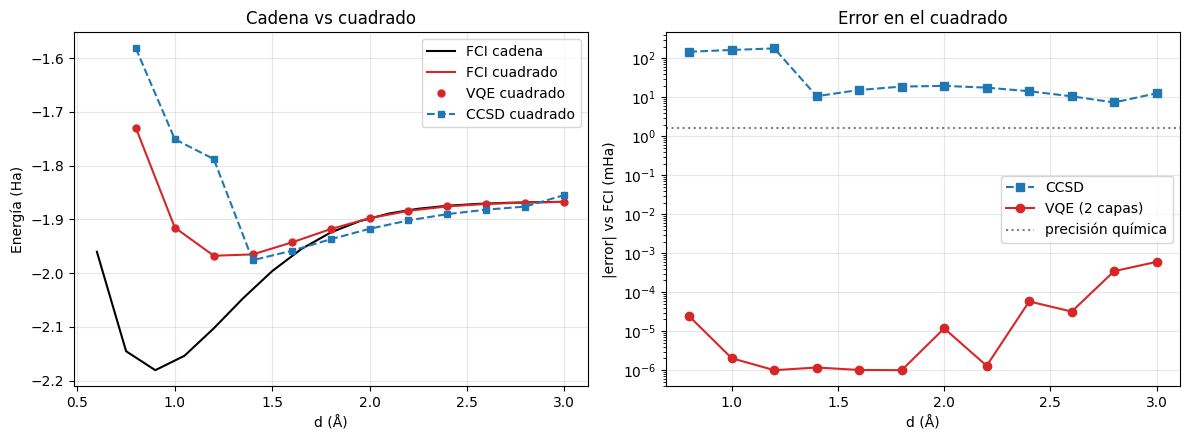

Cuadrado: mínimo de VQE en d = 1.2 Å, energía de disociación (d = 3,0 Å) = 100.1 mHa


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Energías: cadena vs cuadrado
ax[0].plot([x["d"] for x in problemas_h4], [x["e_fci"] for x in problemas_h4], "k-", label="FCI cadena")
ax[0].plot([x["d"] for x in problemas_cuad], [x["e_fci"] for x in problemas_cuad], "C3-", label="FCI cuadrado")
ax[0].plot([x["d"] for x in problemas_cuad], [x["e_vqe_sin_ruido"] for x in problemas_cuad], "C3o", ms=5, label="VQE cuadrado")
ax[0].plot([x["d"] for x in problemas_cuad], [x["e_ccsd"] for x in problemas_cuad], "C0s--", ms=4, label="CCSD cuadrado")
ax[0].set_xlabel("d (Å)"); ax[0].set_ylabel("Energía (Ha)"); ax[0].set_title("Cadena vs cuadrado")
ax[0].legend(); ax[0].grid(alpha=0.3)

# Errores respecto de FCI en el cuadrado
dc = [x["d"] for x in problemas_cuad]
ax[1].semilogy(dc, [abs(x["e_ccsd"] - x["e_fci"]) * 1000 for x in problemas_cuad], "C0s--", label="CCSD")
ax[1].semilogy(dc, [max(abs(x["e_vqe_sin_ruido"] - x["e_fci"]) * 1000, 1e-6) for x in problemas_cuad], "C3o-", label="VQE (2 capas)")
ax[1].axhline(1.6, color="gray", ls=":", label="precisión química")
ax[1].set_xlabel("d (Å)"); ax[1].set_ylabel("|error| vs FCI (mHa)"); ax[1].set_title("Error en el cuadrado")
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

e_cuad = np.array([x["e_vqe_sin_ruido"] for x in problemas_cuad])
i_min = int(np.argmin(e_cuad))
print(f"Cuadrado: mínimo de VQE en d = {distancias_cuad[i_min]:.1f} Å, "
      f"energía de disociación (d = 3,0 Å) = {(e_cuad[-1] - e_cuad[i_min]) * 1000:.1f} mHa")

Resultados del cuadrado: con dos capas el VQE le pega a FCI en todas las distancias (error del orden de 1e-6 mHa), mientras que CCSD falla por decenas de mHa, y en varios puntos queda por debajo de la energía exacta, algo que un método variacional no puede hacer. Con una sola capa (26 ángulos) el VQE llegó a errores de hasta unos 18 mHa en las pruebas, por eso usamos dos.

De igual modo, hay que tener cuidado con Hartree-Fock en esta geometría: como los orbitales del medio son degenerados, el RHF puede caer en soluciones distintas según la corrida, y eso mueve los errores de CCSD (en algunas distancias dio más de 100 mHa y en otras pocos mHa). FCI y VQE no dependen de eso.